# Tiền xử lý, mất cân bằng và phân loại Toxic/Non Toxic — Mưa Đỏ

**Phạm vi:** BoW/TF-IDF × Multinomial Naive Bayes/Linear SVM. Chưa làm PhoBERT.
Notebook đọc các kết quả đã chạy; code nghiệp vụ được tách ở `preprocessing`, `training`, `evaluation`.
Để kiểm tra kết quả hiện có: chọn kernel `.venv`, **Run All**, giữ `RUN_TRAINING = False`.

**Hạn chế nhãn:** File có nhãn do ChatGPT đánh giá, một phần gốc còn `needs_review` và các biến thể tổng hợp chưa được duyệt thủ công.
Các điểm số đo mức khớp nhãn được cung cấp, không thay thế đánh giá trên nhãn chuẩn do người gán độc lập.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'phien_ban_moi/training/run_all.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
PACKAGE = ROOT / 'phien_ban_moi'
RESULTS = PACKAGE / 'results'
RUN_TRAINING = False
INPUT_FILE = None  # Khi chạy lại: Path(...) đến CSV đầu vào hoặc snapshot trong data/input.
pd.set_option('display.max_colwidth', 130)
pd.set_option('display.max_columns', 14)

if RUN_TRAINING:
    from phien_ban_moi.training.run_all import run
    if INPUT_FILE is None:
        raise ValueError('Chọn INPUT_FILE trước khi bật RUN_TRAINING.')
    RUN_DIR = run(INPUT_FILE)
else:
    latest = RESULTS / 'latest.json'
    if not latest.exists():
        raise FileNotFoundError('Chưa có kết quả. Chạy python -m phien_ban_moi.training.run_all --input FILE trước.')
    RUN_DIR = Path(json.loads(latest.read_text(encoding='utf-8'))['run_dir'])

def read_json(name):
    return json.loads((RUN_DIR/name).read_text(encoding='utf-8'))

metadata = read_json('metadata.json')
audit = read_json('data_audit.json')
splits = read_json('split_stats.json')
print('Kết quả:', RUN_DIR)
print('Nguồn:', metadata['input_snapshot'])
print('SHA256:', metadata['input_sha256'])
print('Trạng thái:', read_json('run_status.json'))

Kết quả: C:\Users\ASUS\Study\KHDL\NLP\BTL1-NLP\phien_ban_moi\results\20261106_100533_38153ca8
Nguồn: C:\Users\ASUS\Study\KHDL\NLP\BTL1-NLP\phien_ban_moi\data\input\labels_38153ca83205.csv
SHA256: 38153ca83205d025e6782b668ccf4a06ad5eb32cc320bdb15ccd64e121da03f6
Trạng thái: {'status': 'complete', 'models': 12, 'model_reload_verified': True}


## 1. Dữ liệu và nhãn đầu vào

Tách bình luận gốc khỏi tổng hợp trước khi chia tập. Quy ước `non-toxic = 0`, `toxic = 1`.
Không tự chuyển cờ cần duyệt thành đã duyệt. Không dùng `reason`, `review_status`, `assessment_method` làm đặc trưng dự đoán.

In [2]:
snapshot = pd.read_csv(metadata['input_snapshot'], dtype=str, keep_default_na=False)
display(pd.crosstab(snapshot.is_synthetic, snapshot.label).rename_axis('is_synthetic'))
display(pd.crosstab(snapshot.is_synthetic, snapshot.needs_review).rename_axis('is_synthetic'))
display(Markdown(f"**Nhận xét:** File có {audit['original_input']:,} bình luận gốc và {audit['synthetic_input']:,} dòng tổng hợp. "
                 f"Có {audit['needs_review_original_input']:,} dòng gốc còn needs_review. Tổng hợp không được cộng thành bình luận Facebook mới."))

label,non-toxic,toxic
is_synthetic,,
False,6489,50
True,0,528


needs_review,False,True
is_synthetic,,
False,5545,994
True,0,528


**Nhận xét:** File có 6,539 bình luận gốc và 528 dòng tổng hợp. Có 994 dòng gốc còn needs_review. Tổng hợp không được cộng thành bình luận Facebook mới.

## 2. Làm sạch, chuẩn hóa và tách từ

Giữ `text_raw`; chuẩn Unicode, từ viết tắt, URL, emoji thành token và tách từ tiếng Việt bằng underthesea.
Giữ phủ định, từ tục, bình luận ngắn; không loại stop words mặc định.
Các nhóm gốc có cùng nội dung/token nhưng nhãn khác nhau được cách ly để duyệt lại.

In [3]:
original = pd.read_csv(RUN_DIR/'data/original_clean.csv', dtype=str, keep_default_na=False)
excluded = pd.read_csv(RUN_DIR/'data/excluded_rows.csv', dtype=str, keep_default_na=False)
display(original[['text_raw', 'text_normalized', 'text_processed', 'label', 'needs_review']].head(5))
display(pd.Series(audit['exclusions'], name='số_dòng').to_frame())
conflicts = excluded.loc[excluded.excluded_reason.eq('conflicting_original_labels')]
display(conflicts[['text_raw', 'label', 'post_url', 'excluded_reason']].head(8))
display(Markdown(f"**Nhận xét:** Dùng {audit['original_used']:,} bình luận gốc sau làm sạch. "
                 f"Có {len(conflicts)} dòng gốc nhãn mâu thuẫn được cách ly, không tự chọn một nhãn."))

,text_raw,text_normalized,text_processed,label,needs_review
0,🎟️ Suất chiếu đặc biệt từ 18h00 ngày 21.8.2025 🎟️ Khởi chiếu tại rạp: 22.8.2025 👉 Các chiến sĩ ra trận bảo vệ Thành cổ tại: ht...,emoji_admission_tickets suất chiếu đặc biệt từ 18h00 ngày 21.8.2025 emoji_admission_tickets khởi chiếu tại rạp: 22.8.2025 emoj...,emoji_admission_tickets suất chiếu đặc_biệt từ 18 h00 ngày 21.8.2025 emoji_admission_tickets khởi_chiếu tại rạp : 22.8.2025 em...,0,True
1,"Cho mình xin lịch chiếu với ad ơi. Bố mình từng chiến đấu ở chiến trường Quảng Trị, mình muốn đưa ông đi xem bộ phim này.","cho mình xin lịch chiếu với ad ơi. bố mình từng chiến đấu ở chiến trường quảng trị, mình muốn đưa ông đi xem bộ phim này.","cho mình xin lịch_chiếu với ad ơi . bố mình từng chiến_đấu ở chiến_trường quảng_trị , mình muốn đưa ông đi xem bộ phim này .",0,False
2,Sẵn sàng 🫡,sẵn sàng emoji_saluting_face,sẵn_sàng emoji_saluting_face,0,False
3,Thử đặt quân Mỹ vào bối cảnh giống quân GP chắc 100% Mỹ đéo bao h dám đánh luôn,thử đặt quân mỹ vào bối cảnh giống quân gp chắc 100% mỹ đéo bao h dám đánh luôn,thử đặt quân_mỹ vào bối_cảnh giống quân gp chắc 100 % mỹ_đéo bao_h dám đánh luôn,0,False
4,Ôi thành cổ . Oanh liệt ý trí sắt đá của các chiến sĩ đã dành lại độc lập .,ôi thành cổ . oanh liệt ý trí sắt đá của các chiến sĩ đã dành lại độc lập .,ôi thành cổ . oanh_liệt ý_trí sắt đá của các chiến_sĩ đã dành lại độc_lập .,0,False


,số_dòng
duplicate_original_content,502
empty_text_or_source_or_id,4
conflicting_original_labels,2


,text_raw,label,post_url,excluded_reason
4,Thằng này chuyên gia giựt tiền và lừa đảo,1,https://www.facebook.com/PhimMuaDo/posts/pfbid02PTyV4AENYRGjKDktiEeiDXRxd75Rn4g4utEmEL4vfnLKt7cvjEKnXCH7feZ4XS2Gl/,conflicting_original_labels
5,Thằng này chuyên gia giựt tiền và lừa đảo,0,https://www.facebook.com/PhimMuaDo/posts/pfbid0KSNmaM2osWMfvqXhUY2FsPWxeoSik6GbmmPhQ5qX8UmscGbFhLwtyRv4GAW42tCLl/,conflicting_original_labels


**Nhận xét:** Dùng 6,031 bình luận gốc sau làm sạch. Có 2 dòng gốc nhãn mâu thuẫn được cách ly, không tự chọn một nhãn.

## 3. Chia train/validation/test theo bài

Mục tiêu 80/10/10; số mẫu thực có thể lệch do mỗi bài phải nằm trọn trong một tập.
Cách chia chỉ xét nhóm và nhãn để giữ hai lớp, không dùng điểm mô hình để tìm tập test thuận lợi.
Validation và test giữ phân bố gốc; không chứa tổng hợp hoặc oversampling.

In [4]:
split_table = pd.DataFrame([
    {'tập': name, 'số_dòng': splits[name]['rows'], 'số_bài': splits[name]['posts'],
     'Non Toxic': splits[name]['labels'].get('0', 0), 'Toxic': splits[name]['labels'].get('1', 0)}
    for name in ['train', 'validation', 'test']])
split_table['tỷ_lệ_%'] = (split_table['số_dòng']/split_table['số_dòng'].sum()*100).round(2)
display(split_table)
frames = {name: pd.read_csv(RUN_DIR/f'data/{name}.csv', dtype=str, keep_default_na=False)
          for name in ['train', 'validation', 'test']}
for a, b in [('train','validation'), ('train','test'), ('validation','test')]:
    assert not set(frames[a].post_id) & set(frames[b].post_id)
    assert not set(frames[a].text_hash) & set(frames[b].text_hash)
assert frames['test'].is_synthetic.str.lower().eq('false').all()
assert frames['validation'].is_synthetic.str.lower().eq('false').all()
print('Đạt kiểm tra: không trùng bài/nội dung giữa 3 tập; test/validation không có synthetic.')

Đạt kiểm tra: không trùng bài/nội dung giữa 3 tập; test/validation không có synthetic.


,tập,số_dòng,số_bài,Non Toxic,Toxic,tỷ_lệ_%
0,train,4673,76,4635,38,77.48
1,validation,788,10,783,5,13.07
2,test,570,10,564,6,9.45


## 4. Kiểm tra nguồn gốc các biến thể tổng hợp

Chỉ dùng biến thể có cha còn trong train gốc và nhãn khớp cha; loại biến thể trùng nội dung gốc hoặc trùng nhau.
Biến thể của cha thuộc validation/test, của cha bị cách ly hoặc cha không tìm thấy đều không được dùng.

In [5]:
eligibility = pd.read_csv(RUN_DIR/'data/synthetic_eligibility.csv', dtype=str, keep_default_na=False)
synthetic_train = pd.read_csv(RUN_DIR/'data/synthetic_train.csv', dtype=str, keep_default_na=False)
display(eligibility.eligibility.value_counts().rename('số_biến_thể').to_frame())
assert synthetic_train.parent_source_key.isin(frames['train'].source_key).all()
assert not synthetic_train.text_hash.isin(frames['validation'].text_hash).any()
assert not synthetic_train.text_hash.isin(frames['test'].text_hash).any()
display(Markdown(f"**Nhận xét:** Chỉ {len(synthetic_train)} biến thể được dùng ở kịch bản augmented_ros. "
                 'Điểm test không được tính trên các câu được tạo tổng hợp.'))

,số_biến_thể
eligibility,
eligible,414
source_parent_not_in_original_train,108
duplicate_synthetic_content,6


**Nhận xét:** Chỉ 414 biến thể được dùng ở kịch bản augmented_ros. Điểm test không được tính trên các câu được tạo tổng hợp.

## 5. Xử lý mất cân bằng chỉ trên train

So sánh ba kịch bản trên cùng dữ liệu test:

1. **original_imbalanced:** chỉ train gốc, chưa cân bằng.
2. **original_ros:** train gốc + Random Oversampling, nhân bản lớp ít đến số mẫu lớp nhiều.
3. **augmented_ros:** train gốc + biến thể tổng hợp hợp lệ, sau đó Random Oversampling.

Từ vựng và IDF chỉ học trên pool train **trước** ROS; các chỉ số mẫu lấy lại nằm trong `data/*_sampling.csv`.

,scenario,label,before_ros,after_ros,synthetic_before_ros
0,original_imbalanced,0,4635,4635,0
1,original_imbalanced,1,38,38,0
2,original_ros,0,4635,4635,0
3,original_ros,1,38,4635,0
4,augmented_ros,0,4635,4635,0
5,augmented_ros,1,452,4635,414


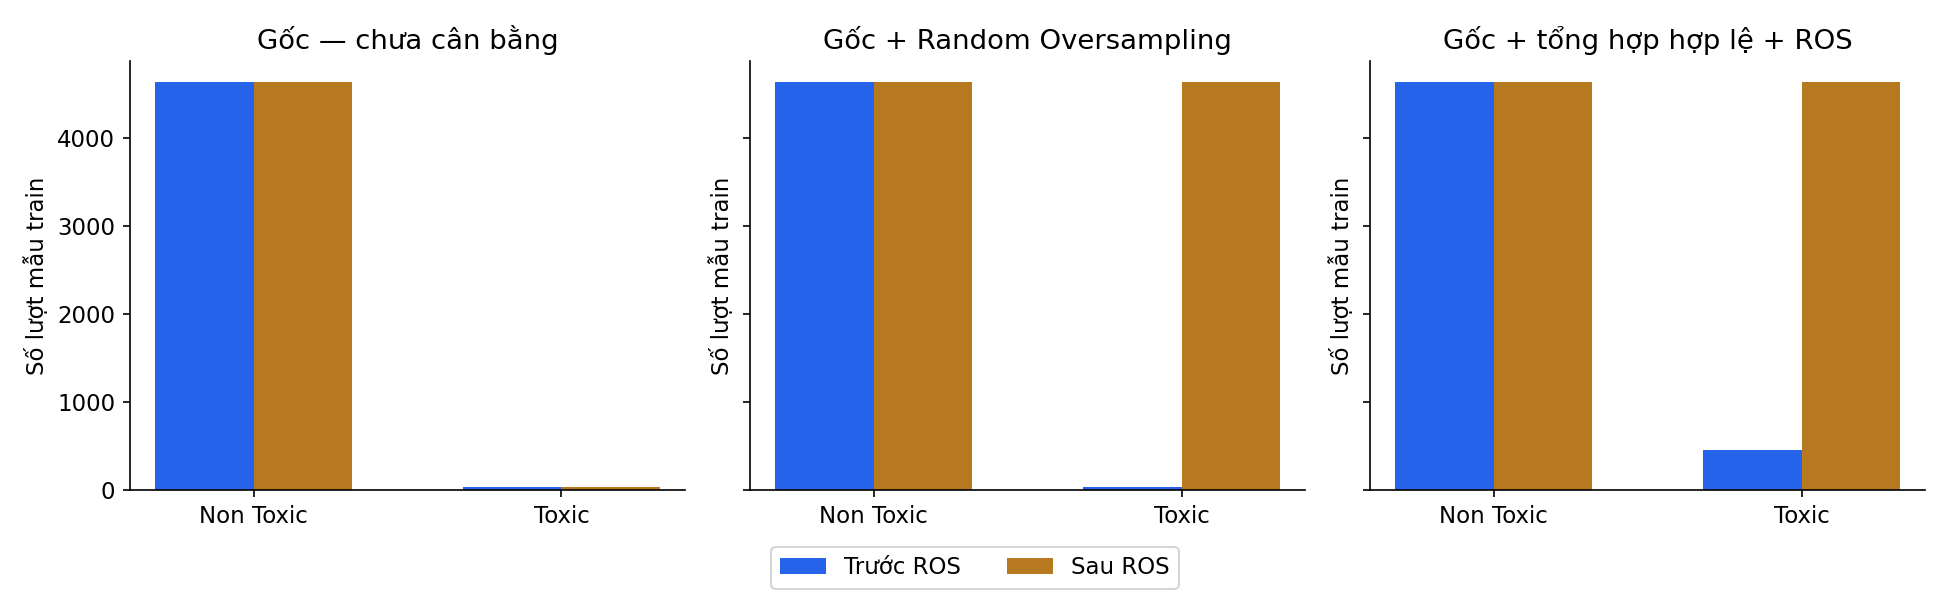

**Baseline chỉ đoán Non Toxic:** Accuracy 0.989, Macro-F1 0.497, Recall Toxic = 0. Vì vậy cần xem Macro-F1 và Recall/F1 Toxic, không kết luận từ Accuracy riêng lẻ.

In [6]:
balance = pd.read_csv(RUN_DIR/'train_class_balance.csv')
display(balance)
display(Image(filename=str(RUN_DIR/'figures/class_balance.png')))
baseline = read_json('majority_baseline.json')
display(Markdown(f"**Baseline chỉ đoán Non Toxic:** Accuracy {baseline['accuracy']:.3f}, "
                 f"Macro-F1 {baseline['macro_f1']:.3f}, Recall Toxic = 0. "
                 'Vì vậy cần xem Macro-F1 và Recall/F1 Toxic, không kết luận từ Accuracy riêng lẻ.'))

## 6. Bốn cấu hình mô hình và chọn tham số

BoW + NB, TF-IDF + NB, BoW + SVM, TF-IDF + SVM; mỗi cấu hình chạy cả ba kịch bản, tổng cộng 12 kết quả.
Thử unigram và unigram+bigram; NB `alpha ∈ {0.1, 0.5, 1}`, SVM `C ∈ {0.1, 1, 10}`.
Chọn tham số và mô hình theo **Macro-F1 validation**; không dùng test để chọn.

In [7]:
selection = pd.read_csv(RUN_DIR/'validation_selection.csv')
display(selection[['scenario','feature','algorithm','ngram','parameter','validation_macro_f1','fit_seconds']])
chosen = read_json('selected_model_before_test.json')
assert not chosen['test_used_for_selection']
assert chosen['selected_model'] == metadata['selected_model']
print('Mô hình chốt trước khi đánh giá test:', chosen['selected_model'])

Mô hình chốt trước khi đánh giá test: augmented_ros__BoW__SVM


,scenario,feature,algorithm,ngram,parameter,validation_macro_f1,fit_seconds
0,original_imbalanced,BoW,NB,"(1, 1)",0.5,0.498409,0.184762
1,original_imbalanced,BoW,SVM,"(1, 1)",0.1,0.498409,0.333566
2,original_imbalanced,TF-IDF,NB,"(1, 1)",0.1,0.498409,0.260284
3,original_imbalanced,TF-IDF,SVM,"(1, 1)",0.1,0.498409,0.294752
4,original_ros,BoW,NB,"(1, 1)",0.1,0.495519,0.224922
5,original_ros,BoW,SVM,"(1, 1)",0.1,0.498409,32.339874
6,original_ros,TF-IDF,NB,"(1, 2)",1.0,0.532585,0.915267
7,original_ros,TF-IDF,SVM,"(1, 1)",0.1,0.498409,3.821276
8,augmented_ros,BoW,NB,"(1, 2)",0.1,0.496164,0.835679
9,augmented_ros,BoW,SVM,"(1, 1)",0.1,0.665393,8.848069


## 7. Kết quả trên cùng tập test gốc

Các chỉ số `macro_precision`, `macro_recall`, `macro_f1` cho hai lớp trọng số ngang nhau;
chỉ số `toxic_*` đo riêng lớp Toxic. Support thấp làm điểm Toxic dao động mạnh.

,scenario,feature,algorithm,validation_macro_f1,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_toxic_precision,test_toxic_recall,test_toxic_f1,test_toxic_support
0,original_imbalanced,BoW,NB,0.4984,0.9895,0.4947,0.5000,0.4974,0.0000,0.0000,0.0000,6
1,original_imbalanced,BoW,SVM,0.4984,0.9912,0.9956,0.5833,0.6407,1.0000,0.1667,0.2857,6
2,original_imbalanced,TF-IDF,NB,0.4984,0.9895,0.4947,0.5000,0.4974,0.0000,0.0000,0.0000,6
3,original_imbalanced,TF-IDF,SVM,0.4984,0.9895,0.4947,0.5000,0.4974,0.0000,0.0000,0.0000,6
4,original_ros,BoW,NB,0.4955,0.9842,0.4947,0.4973,0.4960,0.0000,0.0000,0.0000,6
5,original_ros,BoW,SVM,0.4984,0.9930,0.9965,0.6667,0.7482,1.0000,0.3333,0.5000,6
6,original_ros,TF-IDF,NB,0.5326,0.9579,0.5418,0.6489,0.5606,0.0909,0.3333,0.1429,6
7,original_ros,TF-IDF,SVM,0.4984,0.9912,0.8298,0.6658,0.7200,0.6667,0.3333,0.4444,6
8,augmented_ros,BoW,NB,0.4962,0.9807,0.4947,0.4956,0.4951,0.0000,0.0000,0.0000,6
9,augmented_ros,BoW,SVM,0.6654,0.9912,0.9956,0.5833,0.6407,1.0000,0.1667,0.2857,6


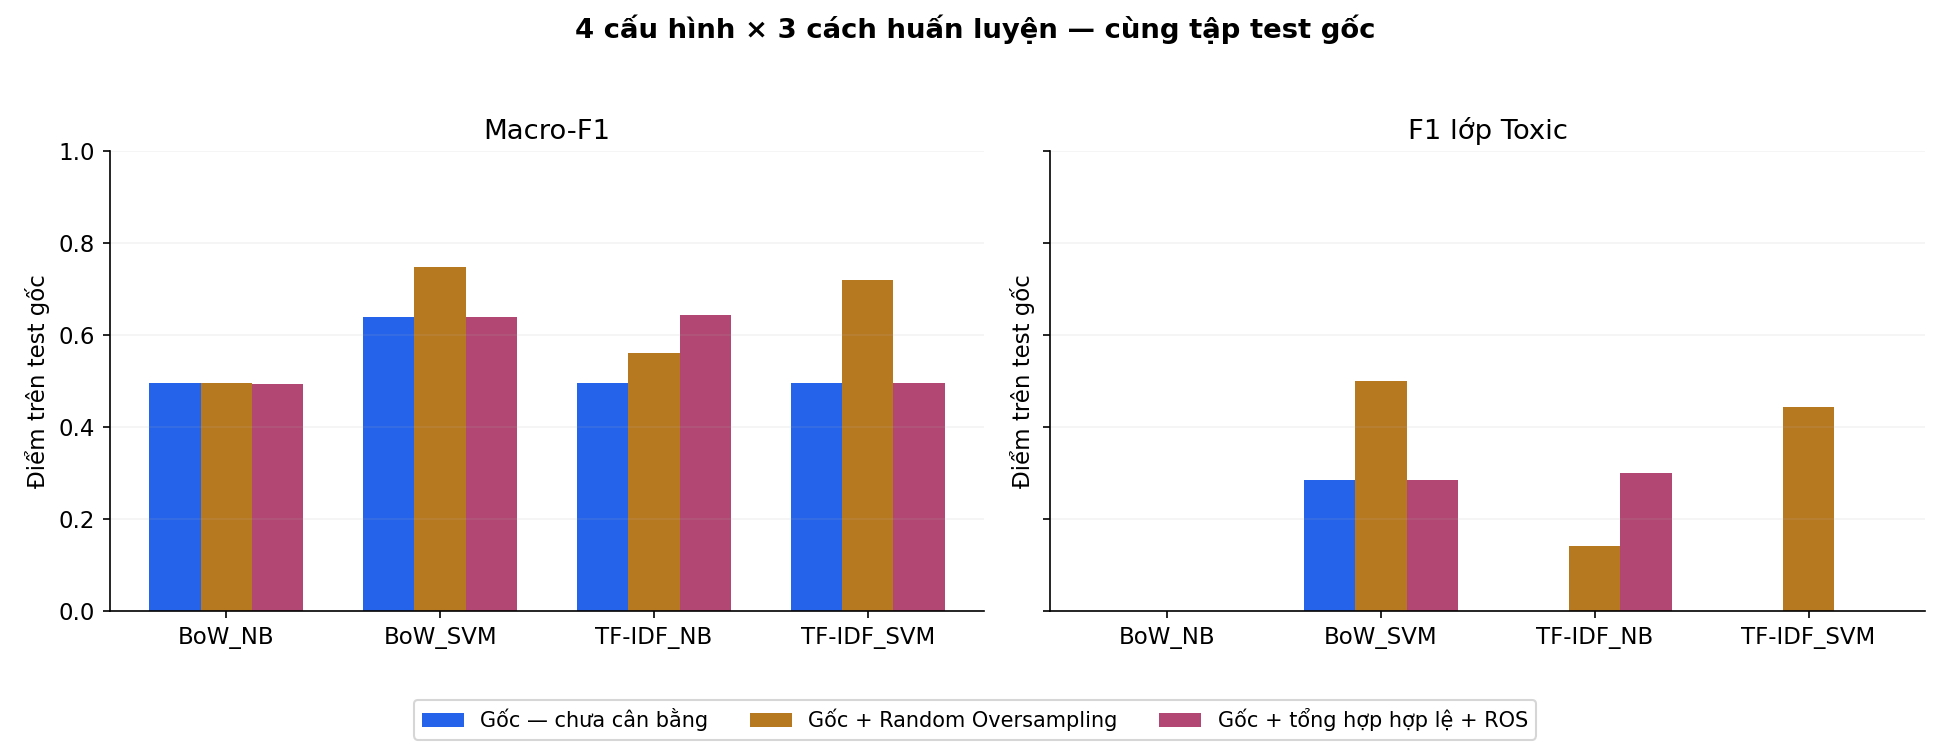

**Mô hình chọn bằng validation:** augmented_ros__BoW__SVM. Test Macro-F1 = 0.641, Toxic F1 = 0.286; test chỉ có 6 mẫu Toxic gốc. Kết quả còn phụ thuộc chất lượng nhãn được cung cấp.

In [8]:
metrics = pd.read_csv(RUN_DIR/'metrics.csv')
display(metrics[['scenario','feature','algorithm','validation_macro_f1','test_accuracy',
                 'test_macro_precision','test_macro_recall','test_macro_f1',
                 'test_toxic_precision','test_toxic_recall','test_toxic_f1','test_toxic_support']].round(4))
display(Image(filename=str(RUN_DIR/'figures/model_comparison.png')))
selected = metrics.set_index('model').loc[metadata['selected_model']]
display(Markdown(f"**Mô hình chọn bằng validation:** {metadata['selected_model']}. "
    f"Test Macro-F1 = {selected.test_macro_f1:.3f}, Toxic F1 = {selected.test_toxic_f1:.3f}; "
    f"test chỉ có {int(selected.test_toxic_support)} mẫu Toxic gốc. Kết quả còn phụ thuộc chất lượng nhãn được cung cấp."))

## 8. Confusion matrix và Precision–Recall

Hàng = nhãn trong file; cột = dự đoán. Các hình dùng cùng một tập test gốc để so sánh.

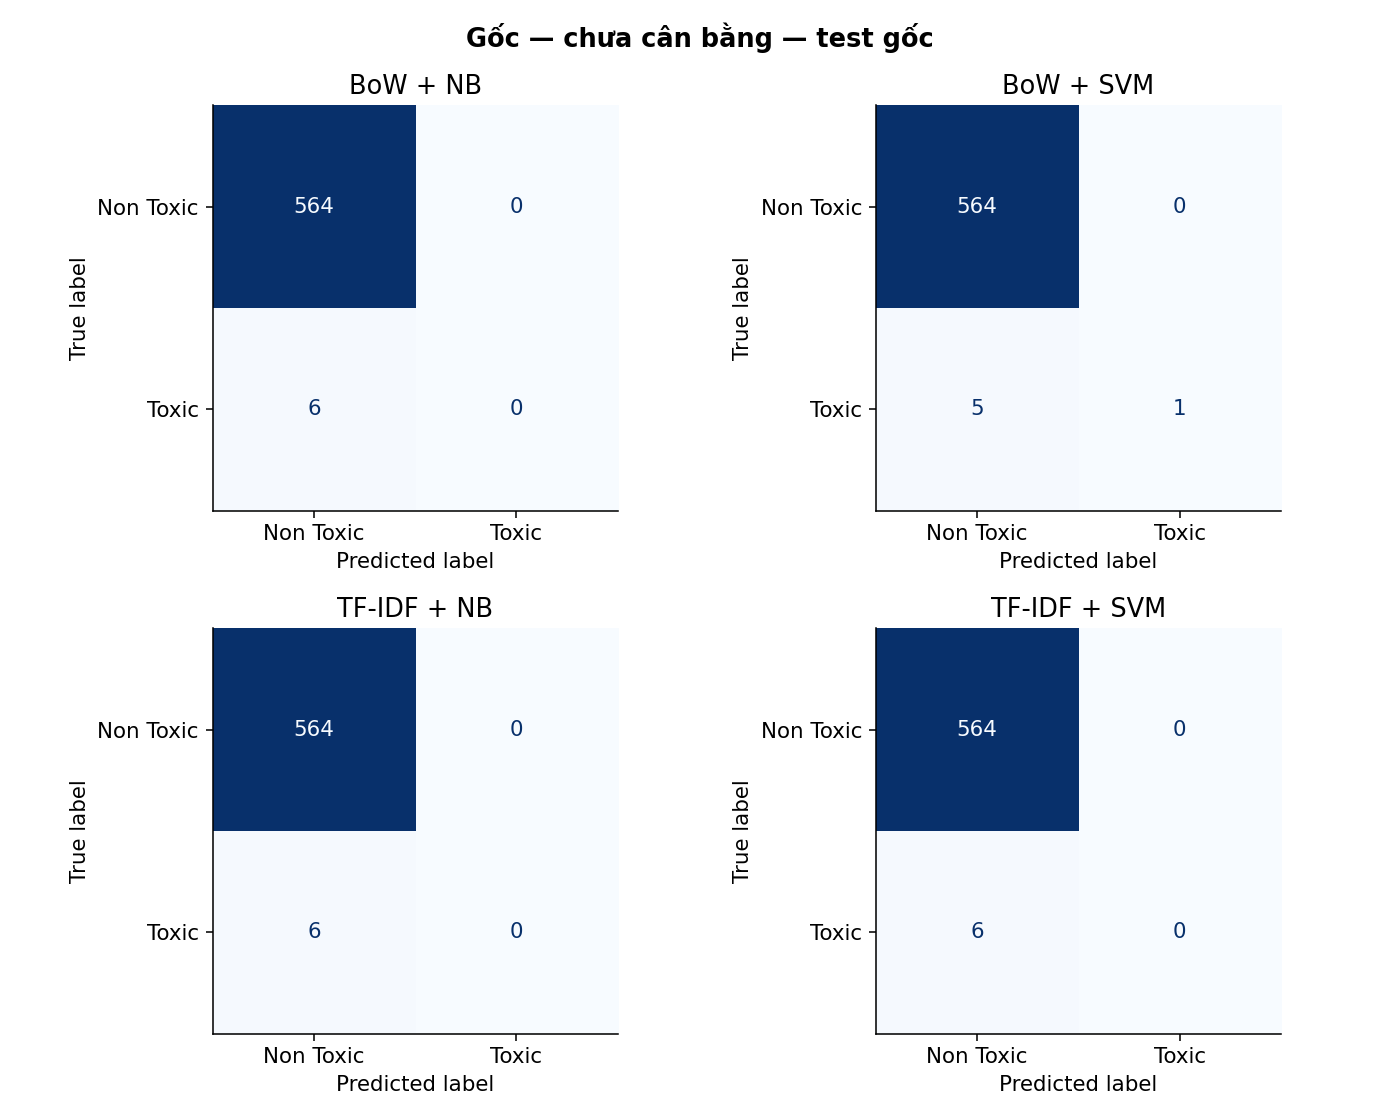

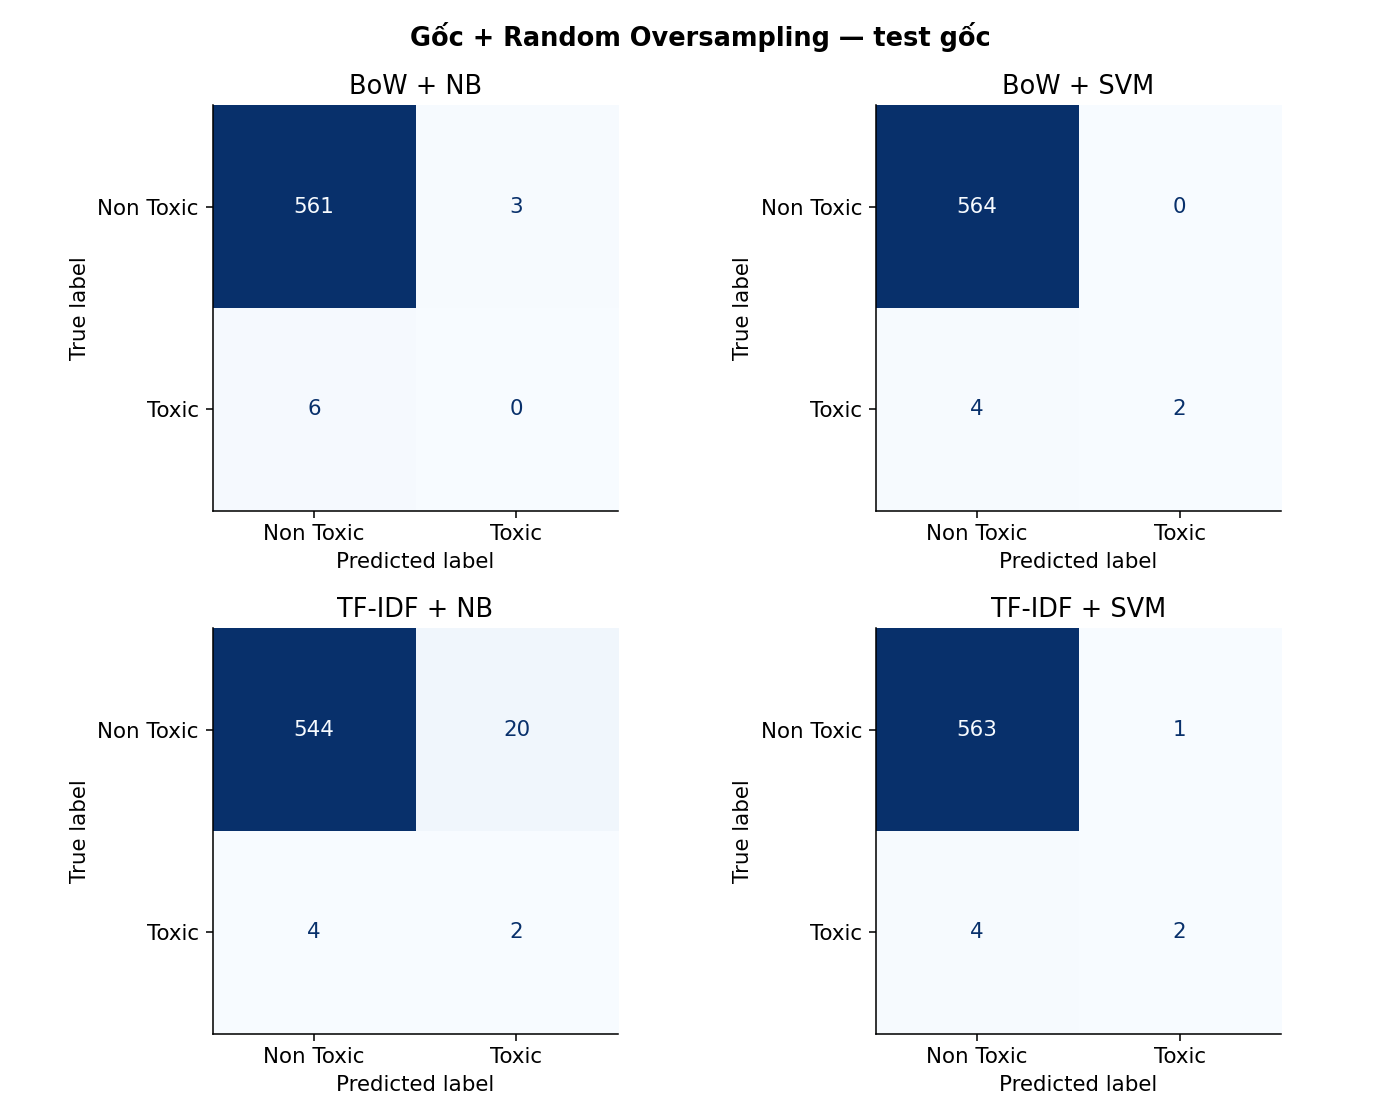

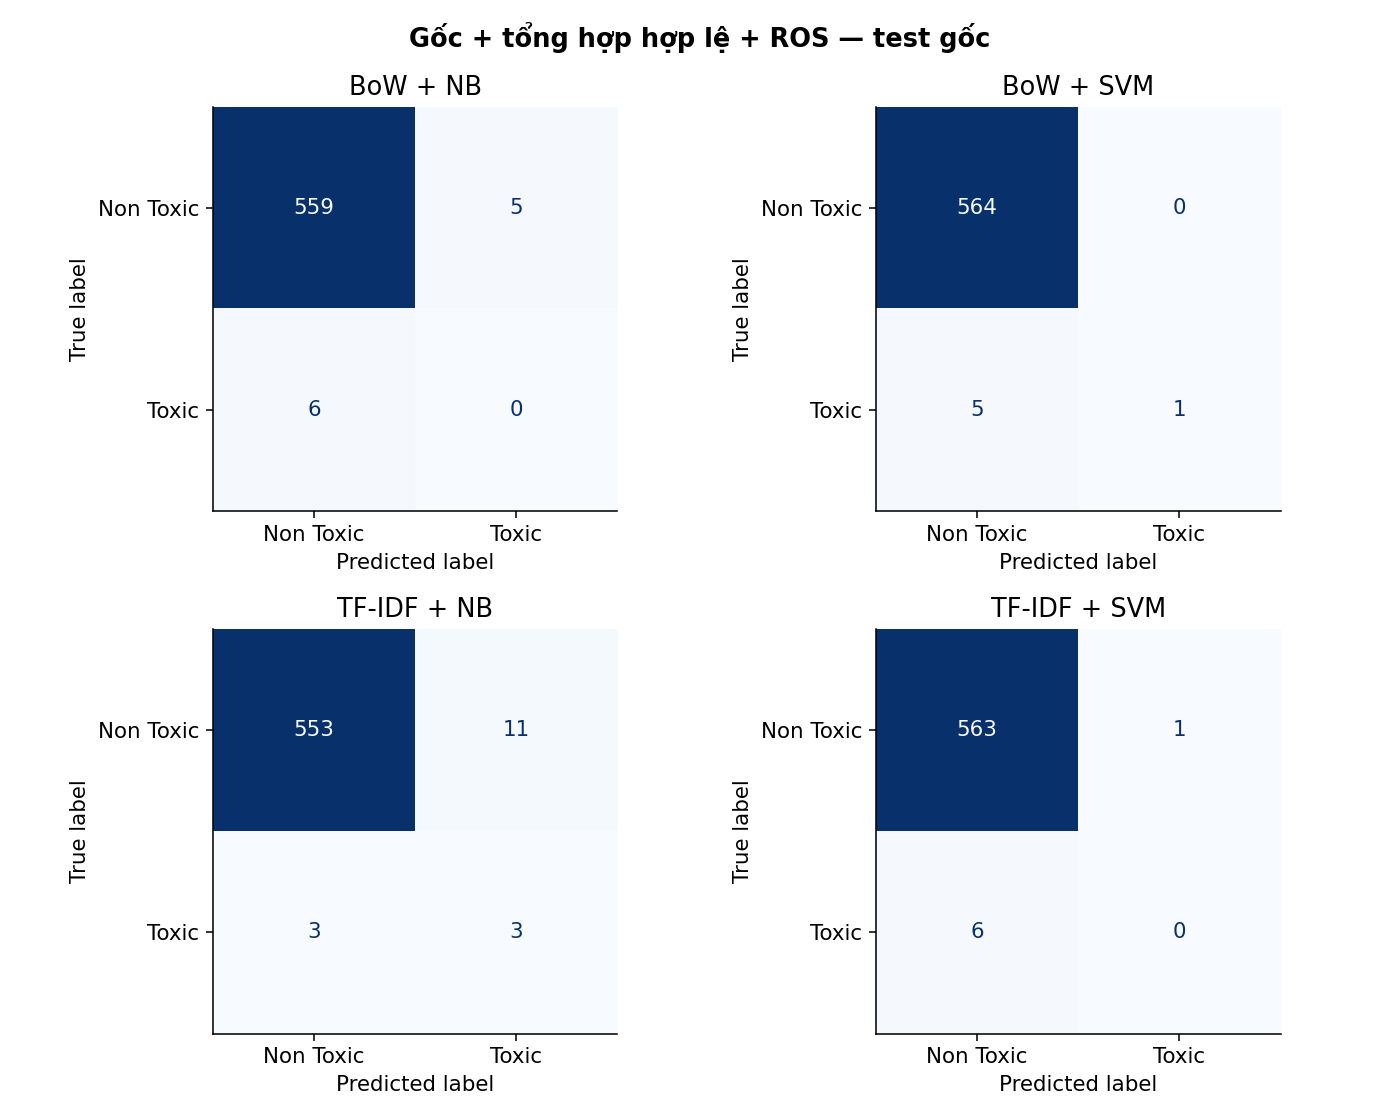

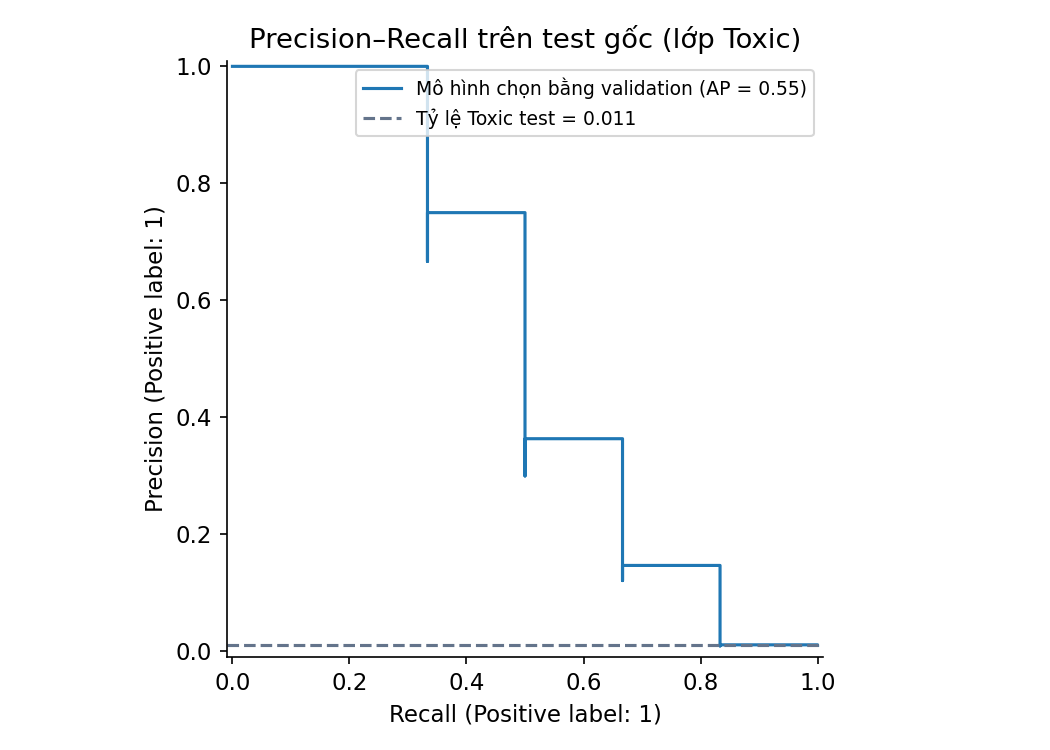

In [9]:
display(Image(filename=str(RUN_DIR/'figures/confusion_original_imbalanced.png')))
display(Image(filename=str(RUN_DIR/'figures/confusion_original_ros.png')))
display(Image(filename=str(RUN_DIR/'figures/confusion_augmented_ros.png')))
display(Image(filename=str(RUN_DIR/'figures/selected_precision_recall.png')))

## 9. Phân tích lỗi của mô hình được chọn

Đọc lỗi để hiểu giới hạn, không sửa nhãn theo dự đoán cho điểm cao hơn.
Nếu điều chỉnh mô hình sau khi xem test, cần một tập test độc lập khác để đánh giá cuối.

In [10]:
errors = pd.read_csv(RUN_DIR/'predictions'/f"{metadata['selected_model']}_errors.csv", dtype=str, keep_default_na=False)
print('Số dự đoán khác nhãn trong file:', len(errors))
display(errors[['text_raw','label','predicted_label','needs_review','review_status','post_url']].head(12))

Số dự đoán khác nhãn trong file: 5


,text_raw,label,predicted_label,needs_review,review_status,post_url
0,Nguyễn Trần Khánh Tuyên mày đến mà đóng,1,0,False,đã đọc toàn văn (bình luận ngắn),https://www.facebook.com/reel/1521398292369988/
1,"Hoá Chất Cơ Bản đang làm ăn kinh tế với họ lại sat trên đầu mà kich động à ,chỉ có que lá mới kich kiểu vậy nhá giờ ai muốn kị...",1,0,True,đã sàng lọc phần đầu; cần đọc đủ toàn văn,https://www.facebook.com/reel/1521398292369988/
2,Hoá Chất Cơ Bản bớt ngu đi bạn .,1,0,False,đã đọc toàn văn (bình luận ngắn),https://www.facebook.com/reel/1521398292369988/
3,Nguyễn Thu Hà que cái đầu nhà chị á. Tui không hề có kích động nha. Nha tui có mấy ông mấy bác hi sinh trong chiến tranh chống...,1,0,True,đã sàng lọc phần đầu; cần đọc đủ toàn văn,https://www.facebook.com/reel/1521398292369988/
4,Chau Hoang tại bạn thiểu năng thì làm sao hiểu được như người bt... chỉ đạo diễn mà bạn gọi là ông thì đủ hiểu bạn là loại gì ...,1,0,False,đã đọc toàn văn (bình luận ngắn),https://www.facebook.com/reel/1521398292369988/


## 10. Nhận xét để viết báo cáo

Các nhận xét dưới đây được tạo từ kết quả thực. Mỗi lần chạy là một thư mục riêng để có thể đối chiếu lại nguồn và cách chia.

In [11]:
report = (RUN_DIR/'reports/nhan_xet_ket_qua.md').read_text(encoding='utf-8')
display(Markdown(report))

# Thực nghiệm Toxic/Non Toxic về Mưa Đỏ

## Phạm vi và chất lượng nhãn

File có 7067 dòng: 6539 gốc và 528 tổng hợp.
Nhãn chữ được đổi thành 0 = Non Toxic, 1 = Toxic. Không đổi ý nghĩa hoặc tự tạo nhãn.
994 dòng gốc được file đánh dấu needs_review.
Các nhãn có nguồn đánh giá ChatGPT; kết quả này đo mức khớp nhãn được cung cấp, **chưa phải đánh giá độc lập trên ground truth con người đã xác nhận**.
Các dòng tổng hợp chưa được duyệt thủ công; xem đây là thử nghiệm tăng cường, không phải dữ liệu Facebook mới.

Sau chuẩn hóa/tách từ, dùng 6031 bình luận gốc.
Các dòng rỗng, trùng hoặc nhãn mâu thuẫn được lưu trong `data/excluded_rows.csv`; không tự sửa nhãn mâu thuẫn.

## Flow

1. Giữ nguyên nguồn và metadata nhãn; chuẩn Unicode, viết tắt, URL, emoji thành token; tách từ bằng underthesea.
2. Cách ly mâu thuẫn, loại trùng khóa/nội dung gốc theo token vectorizer thực sự dùng.
3. Chia gốc theo bài với mục tiêu 80/10/10; chọn cách chia theo nhóm/nhãn, không theo điểm mô hình.
4. Validation/test chỉ có dữ liệu gốc, không oversampling và không có biến thể tổng hợp.
5. Tổng hợp chỉ được dùng nếu cha còn trong train, nhãn khớp cha và nội dung không trùng dữ liệu gốc.
6. BoW/TF-IDF chỉ fit trên pool train trước ROS. ROS lặp mẫu chỉ trong ma trận train.
7. Thử NB alpha = 0.1/0.5/1.0, SVM C = 0.1/1/10; unigram và unigram+bigram. Chọn bằng Macro-F1 validation.
8. Chốt lựa chọn trước khi đọc test; test dùng để báo cáo cuối, không dùng chọn mô hình/tham số.

## Cách chia thực tế

- train: 4673 dòng, 76 bài, số nhãn {'0': 4635, '1': 38}.
- validation: 788 dòng, 10 bài, số nhãn {'0': 783, '1': 5}.
- test: 570 dòng, 10 bài, số nhãn {'0': 564, '1': 6}.

Có 414 biến thể tổng hợp hợp lệ cho train. Các biến thể bị loại và lý do ở `data/synthetic_eligibility.csv`.

## Xử lý mất cân bằng

- `original_imbalanced`: Gốc — chưa cân bằng.
- `original_ros`: Gốc + Random Oversampling.
- `augmented_ros`: Gốc + tổng hợp hợp lệ + ROS.

Mô hình chỉ dự đoán Non Toxic đạt Accuracy 0.9895, Macro-F1 0.4974, Recall Toxic = 0. Vì vậy Accuracy cao không đủ để kết luận mô hình tốt.

## Kết quả trên cùng test gốc

| Cách train | Cấu hình | Val Macro-F1 | Test Accuracy | Test Macro-F1 | Toxic Precision | Toxic Recall | Toxic F1 |
|---|---|---:|---:|---:|---:|---:|---:|
| original_imbalanced | BoW + NB | 0.498 | 0.989 | 0.497 | 0.000 | 0.000 | 0.000 |
| original_imbalanced | BoW + SVM | 0.498 | 0.991 | 0.641 | 1.000 | 0.167 | 0.286 |
| original_imbalanced | TF-IDF + NB | 0.498 | 0.989 | 0.497 | 0.000 | 0.000 | 0.000 |
| original_imbalanced | TF-IDF + SVM | 0.498 | 0.989 | 0.497 | 0.000 | 0.000 | 0.000 |
| original_ros | BoW + NB | 0.496 | 0.984 | 0.496 | 0.000 | 0.000 | 0.000 |
| original_ros | BoW + SVM | 0.498 | 0.993 | 0.748 | 1.000 | 0.333 | 0.500 |
| original_ros | TF-IDF + NB | 0.533 | 0.958 | 0.561 | 0.091 | 0.333 | 0.143 |
| original_ros | TF-IDF + SVM | 0.498 | 0.991 | 0.720 | 0.667 | 0.333 | 0.444 |
| augmented_ros | BoW + NB | 0.496 | 0.981 | 0.495 | 0.000 | 0.000 | 0.000 |
| augmented_ros | BoW + SVM | 0.665 | 0.991 | 0.641 | 1.000 | 0.167 | 0.286 |
| augmented_ros | TF-IDF + NB | 0.564 | 0.975 | 0.644 | 0.214 | 0.500 | 0.300 |
| augmented_ros | TF-IDF + SVM | 0.498 | 0.988 | 0.497 | 0.000 | 0.000 | 0.000 |

## Nhận xét thực nghiệm

- BoW + NB: ROS làm Macro-F1 test thay đổi -0.001; thêm dữ liệu tổng hợp hợp lệ trên nền ROS thay đổi tiếp -0.001.
- BoW + SVM: ROS làm Macro-F1 test thay đổi +0.108; thêm dữ liệu tổng hợp hợp lệ trên nền ROS thay đổi tiếp -0.108.
- TF-IDF + NB: ROS làm Macro-F1 test thay đổi +0.063; thêm dữ liệu tổng hợp hợp lệ trên nền ROS thay đổi tiếp +0.083.
- TF-IDF + SVM: ROS làm Macro-F1 test thay đổi +0.223; thêm dữ liệu tổng hợp hợp lệ trên nền ROS thay đổi tiếp -0.223.

Mô hình chọn bằng validation: **augmented_ros__BoW__SVM**, Val Macro-F1 **0.665**. Trên test: Macro-F1 **0.641**, Toxic Recall **0.167**, Toxic F1 **0.286**.

Test chỉ có **6 mẫu Toxic gốc**; một dự đoán thay đổi có thể làm Recall/F1 dao động mạnh. Khoảng Wilson 95% tham khảo cho Recall Toxic: [0.030, 0.564]. Khoảng này giả sử quan sát độc lập, có thể lạc quan vì bình luận cùng bài có tương quan; không phản ánh sai số nhãn.

Không suy ra ROS hay dữ liệu tổng hợp luôn cải thiện mô hình. Cần duyệt nhãn, bổ sung Toxic thật từ nhiều bài và giữ test độc lập nếu tiếp tục chỉnh mô hình sau khi đọc kết quả.

## Sản phẩm

`metrics.csv`: chỉ số; `validation_search.csv`: tìm tham số; `data/split_manifest.csv`: cách chia; `models/`: mô hình; `predictions/`: dự đoán và lỗi; `figures/`: biểu đồ; `metadata.json`: nguồn, hash, quy tắc, phiên bản. PhoBERT chưa được triển khai theo phạm vi hiện tại.


## 11. Kiểm tra hoàn tất và dự đoán thử (tùy chọn)

Chỉ nạp model do flow này tạo ra. Dự đoán thử là minh họa, không được thêm vào kết quả test.

In [12]:
assert len(metrics) == 12
assert read_json('run_status.json')['status'] == 'complete'
assert read_json('run_status.json')['model_reload_verified']
print('Đủ 4 cấu hình × 3 kịch bản; đã kiểm tra lưu/nạp lại model.')
RUN_DEMO = False
if RUN_DEMO:
    from phien_ban_moi.training.predict import predict
    display(predict(RUN_DIR/'models/selected_model.joblib', [
        'Phim chưa hay nhưng tôi tôn trọng đoàn làm phim.', 'Mày ngu quá, cút đi.']))

Đủ 4 cấu hình × 3 kịch bản; đã kiểm tra lưu/nạp lại model.
